# 03 · Training Data Preparation — PCOS Prediction

**Input:** `data/processed/pcos_clean.csv` (from notebook 01) · **Findings used from** `02_eda.ipynb`

**Outputs**
- `data/processed/train.csv` – training rows (used to fit and tune models)
- `test_data.csv` – held-out test rows (uploaded to the Streamlit app; never used for fitting)
- `model/preprocessor.joblib` – fitted preprocessing pipeline (log + scale + one-hot)

**Steps**
1. Load & define X / y
2. Stratified train/test split
3. Verify the split (no leakage, same class ratio)
4. Group features by the transform they need
5. Build the preprocessing pipeline
6. Fit on **train only**, transform both
7. Verify transformed data
8. Save artifacts

## 1. Setup & load data

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60, "display.width", 200, "display.float_format", "{:,.3f}".format)

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODEL_DIR = ROOT / "model"; MODEL_DIR.mkdir(exist_ok=True)
TARGET = "pcos"
RANDOM_STATE = 26
TEST_SIZE = 0.20

df = pd.read_csv(ROOT / "data" / "processed" / "pcos_clean.csv")
X = df.drop(columns=TARGET)
y = df[TARGET]
print(f"X: {X.shape}   y: {y.shape}   positives: {y.mean():.1%}")
assert df.isna().sum().sum() == 0

X: (541, 41)   y: (541,)   positives: 32.7%


## 2. Train / test split
- **80 / 20**, giving ≈ 108 test rows — small enough for the free Streamlit tier, large enough for stable metrics.
- **Stratified** on the target so both parts keep the ≈ 33 % PCOS share (important with a 2 : 1 imbalance).
- Fixed `random_state` for reproducibility.
- The split happens **before** any fitting (scaling, log transforms) so no test information leaks into training.

In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

summary = pd.DataFrame({
    "rows": [len(df), len(y_train), len(y_test)],
    "PCOS (1)": [y.sum(), y_train.sum(), y_test.sum()],
    "No PCOS (0)": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "PCOS %": [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100],
}, index=["Full", "Train", "Test"])
summary

,rows,PCOS (1),No PCOS (0),PCOS %
Full,541,177,364,32.717
Train,432,141,291,32.639
Test,109,36,73,33.028


## 3. Verify the split

✅ no overlapping rows | sizes add up | class ratio preserved (diff < 1 pp)


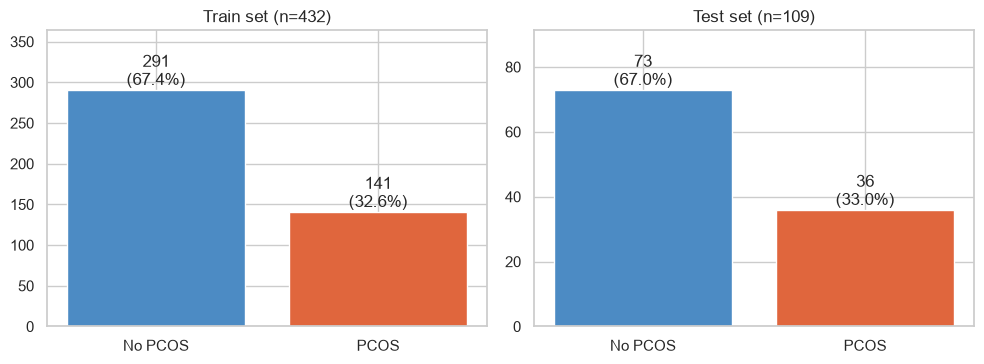

In [3]:
assert set(X_train.index).isdisjoint(X_test.index), "row overlap between train and test!"
assert len(X_train) + len(X_test) == len(X)
assert abs(y_train.mean() - y_test.mean()) < 0.01
print("✅ no overlapping rows | sizes add up | class ratio preserved (diff < 1 pp)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (name, s) in zip(ax, [("Train", y_train), ("Test", y_test)]):
    vc = s.value_counts().sort_index()
    a.bar(["No PCOS", "PCOS"], vc.values, color=["#4c8bc4", "#e0663d"])
    for i, v in enumerate(vc.values): a.text(i, v, f"{v}\n({v/len(s):.1%})", ha="center", va="bottom")
    a.set_title(f"{name} set (n={len(s)})"); a.set_ylim(0, vc.max() * 1.25)
plt.tight_layout(); plt.savefig(FIG / "16_train_test_split.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. Group features by the transform they need
Decided from the EDA, using **training data only** so the choices themselves don't peek at the test set.

| Group | Rule | Transform |
|---|---|---|
| Binary flags | values are only 0 / 1 | pass through (already 0/1) |
| Categorical codes | `blood_group`, `cycle_ri` — numbers that are labels | one-hot encode |
| Skewed numeric | continuous, non-negative, \|skew\| > 1 on train | `log1p` → standardise |
| Other numeric | the rest | standardise |

In [4]:
binary_cols = [col for col in X_train.columns if set(X_train[col].unique()) <= {0, 1}]   # true 0/1 flags only
cat_cols = ["blood_group", "cycle_ri"]
numeric_cols = [col for col in X_train.columns if col not in binary_cols + cat_cols]

skew = X_train[numeric_cols].skew()
log_cols = [col for col in numeric_cols
            if abs(skew[col]) > 1 and X_train[col].min() >= 0 and X_train[col].nunique() > 10]
scale_cols = [col for col in numeric_cols if col not in log_cols]

print(f"Binary ({len(binary_cols)}):        {binary_cols}\n")
print(f"Categorical ({len(cat_cols)}):    {cat_cols}\n")
print(f"Log + scale ({len(log_cols)}):    {log_cols}\n")
print(f"Scale only ({len(scale_cols)}):   {scale_cols}")
assert len(binary_cols) + len(cat_cols) + len(log_cols) + len(scale_cols) == X.shape[1]

Binary (8):        ['pregnant', 'weight_gain', 'hair_growth', 'skin_darkening', 'hair_loss', 'pimples', 'fast_food', 'reg_exercise']

Categorical (2):    ['blood_group', 'cycle_ri']

Log + scale (14):    ['marriage_yrs', 'beta_hcg_1', 'beta_hcg_2', 'fsh', 'lh', 'fsh_lh_ratio', 'tsh', 'amh', 'prl', 'vit_d3', 'prg', 'rbs', 'follicle_l', 'avg_f_size_l']

Scale only (17):   ['age_yrs', 'weight_kg', 'height_cm', 'bmi', 'pulse_rate_bpm', 'resp_rate', 'hb_g_dl', 'cycle_length_days', 'n_abortions', 'hip_inch', 'waist_inch', 'waist_hip_ratio', 'bp_systolic', 'bp_diastolic', 'follicle_r', 'avg_f_size_r', 'endometrium']


,skew_before,skew_after_log1p
prg,20.465,10.305
fsh_lh_ratio,17.442,1.843
vit_d3,14.685,4.328
beta_hcg_2,11.802,1.011
tsh,9.612,1.229
fsh,9.066,0.505
beta_hcg_1,6.781,0.453
rbs,5.622,1.782
amh,3.489,0.387
prl,2.528,-0.436


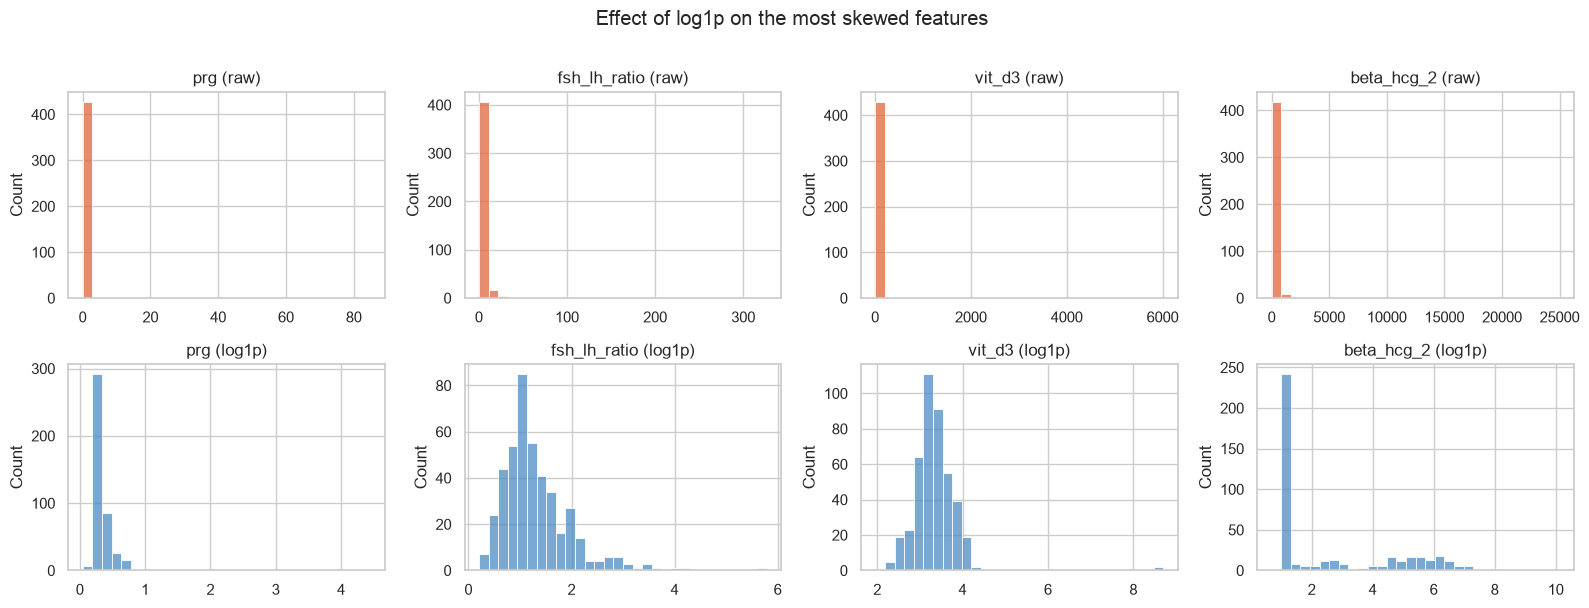

In [5]:
# the skewness of the log-treated columns, before vs after
cmp = pd.DataFrame({"skew_before": X_train[log_cols].skew(), "skew_after_log1p": np.log1p(X_train[log_cols]).skew()})
display(cmp.sort_values("skew_before", ascending=False))

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, col in enumerate(cmp.sort_values("skew_before", ascending=False).index[:4]):
    sns.histplot(X_train[col], bins=30, ax=axes[0, j], color="#e0663d"); axes[0, j].set_title(f"{col} (raw)")
    sns.histplot(np.log1p(X_train[col]), bins=30, ax=axes[1, j], color="#4c8bc4"); axes[1, j].set_title(f"{col} (log1p)")
    axes[0, j].set_xlabel(""); axes[1, j].set_xlabel("")
plt.suptitle("Effect of log1p on the most skewed features", y=1.01)
plt.tight_layout(); plt.savefig(FIG / "17_log_transform_effect.png", dpi=150, bbox_inches="tight"); plt.show()

## 5. Preprocessing pipeline
A single `ColumnTransformer`, so exactly the same steps are applied to training data, test data and any CSV uploaded to the app.
- Missing values were already handled in notebook 01, but a **median imputer** is included so an uploaded file with a blank cell doesn't crash the app.
- Tree models don't need scaling, but they accept scaled input fine, so one shared preprocessor keeps things simple and comparable.

In [6]:
from sklearn.impute import SimpleImputer

log_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                     ("scale", StandardScaler())])
scale_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
bin_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer([
    ("log_scale", log_pipe, log_cols),
    ("scale", scale_pipe, scale_cols),
    ("binary", bin_pipe, binary_cols),
    ("categorical", cat_pipe, cat_cols),
], verbose_feature_names_out=False).set_output(transform="pandas")
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_scale', ...), ('scale', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per tra

## 6. Fit on train only, then transform both sets

In [7]:
preprocessor.fit(X_train)                       # statistics (means, stds, medians, categories) come from TRAIN only
Xtr = preprocessor.transform(X_train)
Xte = preprocessor.transform(X_test)
print("Train:", X_train.shape, "->", Xtr.shape)
print("Test :", X_test.shape,  "->", Xte.shape)
print("(extra columns come from one-hot encoding blood_group and cycle_ri)")
Xtr.head()

Train: (432, 41) -> (432, 50)
Test : (109, 41) -> (109, 50)
(extra columns come from one-hot encoding blood_group and cycle_ri)


,marriage_yrs,beta_hcg_1,beta_hcg_2,fsh,lh,fsh_lh_ratio,tsh,amh,prl,vit_d3,prg,rbs,follicle_l,avg_f_size_l,age_yrs,weight_kg,height_cm,bmi,pulse_rate_bpm,resp_rate,hb_g_dl,cycle_length_days,n_abortions,hip_inch,waist_inch,waist_hip_ratio,bp_systolic,bp_diastolic,follicle_r,avg_f_size_r,endometrium,pregnant,weight_gain,hair_growth,skin_darkening,hair_loss,pimples,fast_food,reg_exercise,blood_group_11,blood_group_12,blood_group_13,blood_group_14,blood_group_15,blood_group_16,blood_group_17,blood_group_18,cycle_ri_2,cycle_ri_4,cycle_ri_5
471,0.110,0.956,-0.735,0.613,-0.809,1.008,-0.413,-1.284,0.727,-0.670,-0.437,-0.602,0.065,0.143,-0.089,-0.863,-0.735,-0.657,2.321,0.461,-0.154,0.020,-0.423,-0.503,0.057,1.088,-0.803,-1.499,1.680,1.402,-0.453,0,0,0,0,1,0,1,0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
324,1.509,-1.016,-0.735,0.610,1.110,-0.749,1.777,-1.256,0.908,0.040,-0.257,0.068,-0.213,-0.816,1.540,0.398,0.248,0.323,0.148,5.244,-0.387,0.020,-0.423,0.266,0.341,0.197,-0.803,0.667,0.099,0.181,0.221,0,1,0,0,0,1,1,1,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
223,-0.386,-1.016,-0.735,0.876,0.823,-0.457,-0.571,0.772,-0.101,0.294,-0.437,-0.258,-0.213,-0.022,-0.270,0.218,2.049,-0.633,-0.577,0.461,1.013,0.020,-0.423,0.009,0.057,-0.026,0.873,-1.499,-0.805,0.792,0.086,0,0,0,0,1,0,1,1,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000
357,0.110,-0.254,0.142,-0.031,0.516,-0.658,-0.684,-0.464,-0.086,-0.641,1.362,0.956,-1.609,-0.022,0.092,-1.133,0.248,-1.343,0.148,0.461,-1.087,0.673,-0.423,-0.247,-0.227,-0.026,-0.803,0.667,-1.256,0.181,-0.947,1,0,1,0,0,1,0,0,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000
264,0.313,0.618,-0.735,0.146,0.066,-0.236,0.504,1.754,0.211,-0.881,-0.406,-0.744,0.988,0.583,0.454,-2.213,-0.244,-2.372,0.148,0.461,1.480,-0.634,-0.423,-1.528,-1.361,0.419,-0.803,-1.499,0.099,0.792,0.221,0,0,0,0,1,1,0,0,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000


## 7. Verify the transformed data

In [8]:
assert Xtr.isna().sum().sum() == 0 and Xte.isna().sum().sum() == 0
assert list(Xtr.columns) == list(Xte.columns)

sc = log_cols + scale_cols
stats = pd.DataFrame({"train_mean": Xtr[sc].mean(), "train_std": Xtr[sc].std(),
                      "test_mean": Xte[sc].mean(), "test_std": Xte[sc].std()})
print("Train columns are centred (mean≈0, std≈1) by construction; test is only approximately so — that is expected and correct.")
print(f"max |train mean| = {stats.train_mean.abs().max():.1e} | train std in [{stats.train_std.min():.2f}, {stats.train_std.max():.2f}]")
print(f"max |test mean|  = {stats.test_mean.abs().max():.2f} | test std in [{stats.test_std.min():.2f}, {stats.test_std.max():.2f}]")
stats.describe().loc[["min", "max"]]

Train columns are centred (mean≈0, std≈1) by construction; test is only approximately so — that is expected and correct.
max |train mean| = 1.8e-15 | train std in [1.00, 1.00]
max |test mean|  = 0.28 | test std in [0.80, 1.19]


,train_mean,train_std,test_mean,test_std
min,-0.000,1.001,-0.282,0.800
max,0.000,1.001,0.187,1.194


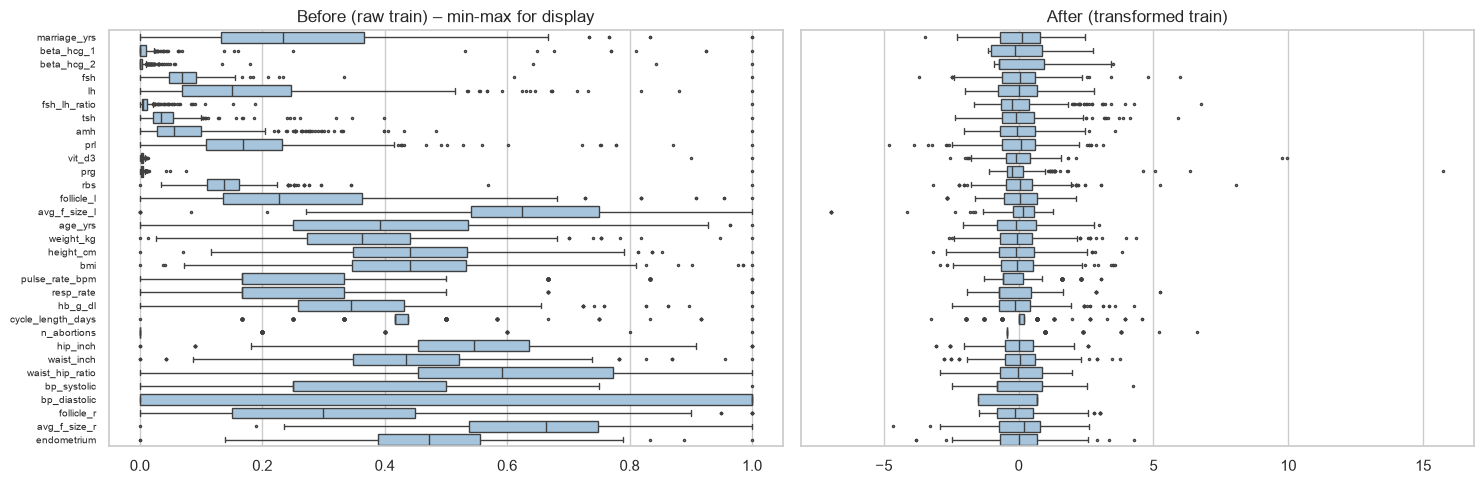

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (name, d) in zip(axes, [("Before (raw train)", X_train[sc]), ("After (transformed train)", Xtr[sc])]):
    z = (d - d.min()) / (d.max() - d.min()) if name.startswith("Before") else d
    sns.boxplot(data=z, orient="h", fliersize=1.5, color="#9ec5e6", ax=ax)
    ax.set_title(name + (" – min-max for display" if name.startswith("Before") else ""))
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.savefig(FIG / "18_before_after_scaling.png", dpi=150, bbox_inches="tight"); plt.show()

In [10]:
# sanity: the transformed training set should still carry the signal seen in the EDA
chk = Xtr.assign(pcos=y_train.values).corr()["pcos"].drop("pcos").abs().sort_values(ascending=False)
print("Top 8 features by |corr| with target after preprocessing:"); print(chk.head(8).round(3).to_string())

Top 8 features by |corr| with target after preprocessing:
follicle_r       0.656
follicle_l       0.553
hair_growth      0.458
skin_darkening   0.449
weight_gain      0.437
fast_food        0.368
cycle_ri_2       0.346
cycle_ri_4       0.340


## 8. Save artifacts
- `train.csv` / `test_data.csv` keep the **raw cleaned columns plus `pcos`** (not the scaled values).
  The Streamlit app needs the unscaled form, because the saved pipeline applies the preprocessing itself.
- The preprocessor is saved on its own now; in the training step it is wrapped together with each classifier so every saved model is self-contained.

In [11]:
train_out = X_train.assign(**{TARGET: y_train}).sort_index()
test_out = X_test.assign(**{TARGET: y_test}).sort_index()

train_out.to_csv(ROOT / "data" / "processed" / "train.csv", index=False)
test_out.to_csv(ROOT / "test_data.csv", index=False)
joblib.dump(preprocessor, MODEL_DIR / "preprocessor.joblib")
joblib.dump({"log_cols": log_cols, "scale_cols": scale_cols, "binary_cols": binary_cols, "cat_cols": cat_cols,
             "feature_order": list(X.columns), "target": TARGET, "random_state": RANDOM_STATE},
            MODEL_DIR / "feature_config.joblib")

# round-trip check: reload from disk and confirm identical output
pp = joblib.load(MODEL_DIR / "preprocessor.joblib")
reload_test = pd.read_csv(ROOT / "test_data.csv")
pd.testing.assert_frame_equal(pp.transform(reload_test[X.columns]).reset_index(drop=True),
                              Xte.sort_index().reset_index(drop=True), check_exact=False, rtol=1e-8)   # CSV is saved in index order
print("Saved:"); 
for p in ["data/processed/train.csv", "test_data.csv", "model/preprocessor.joblib", "model/feature_config.joblib"]:
    print(f"  {p:35s} {(ROOT / p).stat().st_size/1024:8.1f} KB")
print(f"\ntrain.csv: {train_out.shape} | test_data.csv: {test_out.shape}")
print("✅ reloaded preprocessor reproduces the same transformed test set")

Saved:
  data/processed/train.csv                65.8 KB
  test_data.csv                           16.8 KB
  model/preprocessor.joblib                9.2 KB
  model/feature_config.joblib              0.7 KB

train.csv: (432, 42) | test_data.csv: (109, 42)
✅ reloaded preprocessor reproduces the same transformed test set


## Summary
- Stratified **80/20 split** (`random_state=26`): 432 train / 109 test, PCOS share preserved.
- Preprocessing fitted on **train only**: median impute → `log1p` on skewed hormone/lab columns → standardise → one-hot for `blood_group`, `cycle_ri`; binary flags pass through.
- Artifacts written: `train.csv`, `test_data.csv`, `preprocessor.joblib`, `feature_config.joblib`.

**Next:** `src/train.py` — wrap this preprocessor with each of the 5 classifiers, fit on `train.csv`, evaluate on `test_data.csv`, save the models to `model/`.